# Dog detection by fine-tuning a cat detector

We got a Faster R-CNN (MobileNetV3) model trained to detect cats and had to make it detect dogs. I converted the YOLO labels to box coordinates, added augmentations that also move the boxes, froze the backbone and fine-tuned the rest. There is no mAP here, only the training loss and the predictions CSV.

##||IMPORTS||

In [ ]:
!pip install rarfile

In [ ]:
import os
import rarfile
from google.colab import drive

# 2. Google Drive-ის დაკავშირება (Mounting)
# ამ ხაზის გაშვებისას Colab მოგთხოვს ნებართვას შენს დრაივზე წვდომისთვის
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import torch
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from PIL import Image
from pathlib import Path
import json
from torchvision import tv_tensors

In [ ]:
def load_cat_detector(weights_path):
    """Load the pretrained cat detector."""
    # Model architecture: Faster-RCNN with MobileNetV3 backbone
    # Head has 2 classes: background (0) + cat (1)
    model = fasterrcnn_mobilenet_v3_large_fpn(weights=None)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
    model.load_state_dict(torch.load(weights_path, map_location='cpu'))
    return model

weights_pathy = "/content/drive/MyDrive/cat_detector.pth"

model = load_cat_detector(weights_pathy)

In [ ]:
test_pathy = "/content/drive/MyDrive/test_data(2).rar"
train_pathy = "/content/drive/MyDrive/train_data(1).rar"

extract_test = "/content/"
extract_train = "/content/"

# შევქმნათ მიზნობრივი საქაღალდე Drive-ზე, თუ ის ჯერ არ არსებობს
os.makedirs(extract_test, exist_ok=True)
os.makedirs(extract_train, exist_ok=True)

# 3. ფაილის გახსნა და სრული ამოარქივება
with rarfile.RarFile(train_pathy) as rf:
    rf.extractall(path=extract_train)

with rarfile.RarFile(test_pathy) as rf:
    rf.extractall(path=extract_test)

In [ ]:
train_images_dir = "dog_train/images"
train_labels_dir = "dog_train/labels"
test_images_dir = "dog_test/images"

##||IMAGES TO TENSORS||

In [ ]:
def yolo_to_rnn(yolo_bbox, img_width=640, img_height=640):
    # yolo_bbox is a list: [x_center, y_center, width, height]
    x_c, y_c, w, h = yolo_bbox

    x1 = (x_c - w / 2) * img_width
    y1 = (y_c - h / 2) * img_height
    x2 = (x_c + w / 2) * img_width
    y2 = (y_c + h / 2) * img_height

    return [x1, y1, x2, y2]

##||GRAPH IMAGE||

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from torchvision.io import read_image

def plot_rcnn_bbox(image_tensor, target_dict):
    """
    Plots an image with its R-CNN format bounding boxes.

    image_tensor: PyTorch tensor of shape (C, H, W)
    target_dict: Dict containing 'boxes' (N, 4) in XYXY format and 'labels' (N)
    """
    # 1. Permute image tensor from (C, H, W) to (H, W, C) for Matplotlib
    # If your tensor is on GPU, bring it to CPU and convert to numpy
    img = image_tensor.permute(1, 2, 0).cpu().numpy()

    # If your image was normalized (0-1), ensure it's clamped or scaled back to 0-255 if needed

    # 2. Setup the plot
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)

    # 3. Extract boxes and labels
    boxes = target_dict["boxes"].cpu().numpy()
    labels = target_dict["labels"].cpu().numpy()

    # 4. Loop through each box and add it to the plot
    for box, label in zip(boxes, labels):
        xmin, ymin, xmax, ymax = box

        # Calculate width and height for Matplotlib
        width = xmax - xmin
        height = ymax - ymin

        # Create a Rectangle patch
        # (xmin, ymin) is the anchor point (top-left)
        rect = patches.Rectangle(
            (xmin, ymin),
            width,
            height,
            linewidth=2,
            edgecolor="edge_color" if 'edge_color' in locals() else "r", # Red box
            facecolor="none"
        )

        # Add the patch to the Axes
        ax.add_patch(rect)

        # Add the label text just above the top-left corner
        ax.text(
            xmin,
            ymin - 5,
            f"Class: {label}",
            color="white",
            bbox=dict(facecolor="red", alpha=0.5, boxstyle="round,pad=0.2")
        )

    plt.axis("off") # Hide grid lines and tick labels
    plt.show()

# --- Example Usage ---
# Assuming you have an image tensor named 'augmented_img'
# and your R-CNN target dictionary named 'target_dict'
# plot_rcnn_bbox(augmented_img, target_dict)

#|||PLAYGROUND|||

In [ ]:
bimbo = "000000091612"
with open(f"dog_train/labels/{bimbo}.txt", "r", encoding="utf-8") as file:
    # Read the content and apply .strip()
    clean_text = file.read().strip()
flat_list = [float(x) for x in clean_text.split()]
classes = []
boxes = []

    # Loop through the list 5 elements at a time
for i in range(0, len(flat_list), 5):
        chunk = flat_list[i : i + 5]
        classes.append(chunk[0])     # First element is the class ID
        boxes.append(yolo_to_rnn(chunk[1:]))      # The next 4 elements are the coordinates

boxes_tensor = torch.tensor(boxes, dtype=torch.float32)
img_tensor = read_image(f"dog_train/images/{bimbo}.jpg")

# Optional: Convert to float32 scaled between 0 and 1 (standard for training)
img = img_tensor.float() / 255.0

In [ ]:
y_train_boxes[0]

tensor([[368.3585, 455.0329, 484.7888, 532.8292]])

tensor([[176.3901,  91.5098, 427.1402, 423.5300],
        [401.3997,  13.7298, 453.6198,  84.9499]])


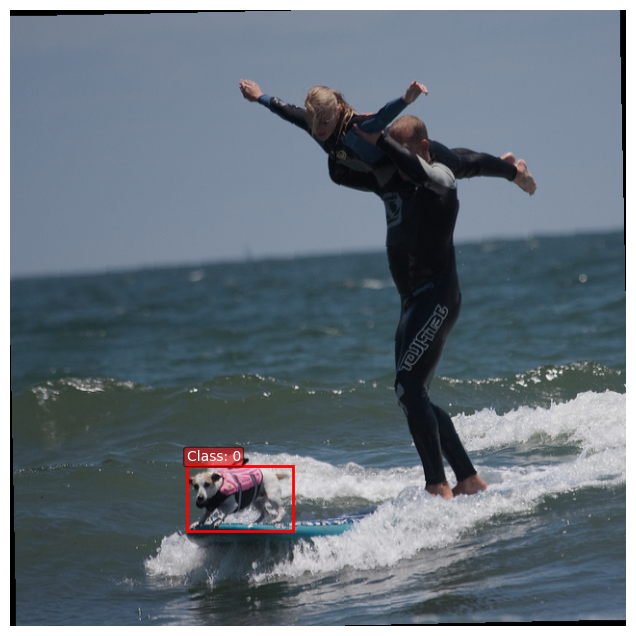

torch.Size([3, 428, 640])

In [ ]:
ind = 5
idx = 10
print(boxes_tensor)
mock_target = {
    "boxes": y_train_boxes[idx],
    # Creating dummy labels (all zeros) matching the number of boxes
    "labels": torch.zeros(len(boxes_tensor), dtype=torch.int64)
}

plot_rcnn_bbox(X_train_images[idx], mock_target)
img.shape

##||AUGMENTATIONS||

In [ ]:
import torchvision.transforms.v2 as transforms
augmentation_pipeline = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.RandomHorizontalFlip(p=0.3), # 50% chance to flip horizontally
    transforms.RandomVerticalFlip(p=0.3),   # 50% chance to flip vertically

    transforms.RandomRotation(degrees=(-10, 10)),   # Slight rotations (-15 to +15 degrees)

    # Color transformations are smart: they automatically ignore masks and only modify images
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])

In [ ]:
import os
import torch
import torchvision.transforms.v2.functional as F
from torchvision import tv_tensors
from PIL import Image

def load_and_augment_rcnn_data(image_dir, label_dir, augmentation_pipeline=None, mult_factor=1, target_size=(640, 640)):
    file_names = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    label_names = sorted([f for f in os.listdir(label_dir) if f.lower().endswith('.txt')])

    output_images = []
    output_boxes = []

    for idx in range(len(file_names)):
        img_path = os.path.join(image_dir, file_names[idx])
        label_path = os.path.join(label_dir, label_names[idx])

        # 1. Open image using PIL and get raw metrics
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            orig_img = F.to_image(img) # Convert PIL to Tensor (C, H, W)

        c, h, w = orig_img.shape

        # 2. Read text labels and convert normalized YOLO (CXCYWH) -> Absolute R-CNN (XYXY)
        boxes = []
        if os.path.exists(label_path):
            with open(label_path, "r", encoding="utf-8") as file:
                clean_text = file.read().strip()

            flat_list = [float(x) for x in clean_text.split()]

            # Use 'box_idx' to avoid shadowing our outer index loop!
            for box_idx in range(0, len(flat_list), 5):
                chunk = flat_list[box_idx : box_idx + 5]
                if len(chunk) == 5:
                    # chunk[0] is class_id; chunk[1:5] are [cx, cy, bw, bh]
                    cx, cy, bw, bh = chunk[1], chunk[2], chunk[3], chunk[4]

                    # Convert normalized YOLO -> Absolute XYXY coordinates
                    xmin = (cx - bw / 2.0) * w
                    ymin = (cy - bh / 2.0) * h
                    xmax = (cx + bw / 2.0) * w
                    ymax = (cy + bh / 2.0) * h
                    boxes.append([xmin, ymin, xmax, ymax])

        # If file is empty, handle an empty bounding box tensor gracefully
        if len(boxes) == 0:
            boxes_tensor = torch.zeros((0, 4), dtype=torch.float32)
        else:
            boxes_tensor = torch.tensor(boxes, dtype=torch.float32)

        # 3. Securely pack items into Torchvision v2 TV-Tensors
        target_boxes = tv_tensors.BoundingBoxes(
            boxes_tensor,
            format="XYXY",
            canvas_size=(h, w)
        )
        # Scale pixel values to floats between 0.0 and 1.0
        orig_img = tv_tensors.Image(orig_img.float() / 255.0)

        # 4. Loop through the multiplication factor to apply your augmentations
        for j in range(mult_factor):
            if augmentation_pipeline is not None:
                # Synchronously transforms image pixels AND bounding box coordinates
                aug_img, aug_boxes = augmentation_pipeline(orig_img, target_boxes)
            else:
                aug_img, aug_boxes = orig_img, target_boxes

            # Resize both the image and the box boundaries to your final uniform target size (e.g. 640x640)
            aug_img = F.resize(aug_img, size=target_size)
            aug_boxes = F.resize(aug_boxes, size=target_size)

            # Strip down tv_tensor types back into standard PyTorch Tensors for training
            output_images.append(aug_img.as_subclass(torch.Tensor))
            output_boxes.append(aug_boxes.as_subclass(torch.Tensor))
    output_images = torch.stack(output_images, dim=0)
    return output_images, output_boxes

# ==========================================================
# EXAMPLE USAGE
# ==========================================================
# Assuming your paths point to your project workspace directories:

# Load input images (Shape will be: [N, 3, 256, 256])
X_train_images, y_train_boxes = load_and_augment_rcnn_data(
    train_images_dir, train_labels_dir,
    augmentation_pipeline=augmentation_pipeline,
    mult_factor=20,
    target_size=(640, 640)
)
print("\nLoading complete!")


Loading complete!


In [ ]:
def load_test_images_only(image_dir, target_size=(640, 640)):
    """Loads and resizes images from a directory without requiring any labels."""
    # Grab all image files from the directory
    file_names = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    test_images = []

    for img_name in file_names:
        img_path = os.path.join(image_dir, img_name)

        # 1. Open the image safely using PIL
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            # Convert PIL image to Torchvision Tensor (C, H, W)
            orig_img = F.to_image(img)

        # 2. Scale pixel values to floats between 0.0 and 1.0
        img_tensor = orig_img.float() / 255.0

        # 3. Resize to your uniform target training size (640, 640)
        img_resized = F.resize(img_tensor, size=target_size)

        # 4. Strip the Torchvision structure back to a standard PyTorch Tensor
        test_images.append(img_resized.as_subclass(torch.Tensor))

    print(f"✅ Loaded {len(test_images)} test images successfully!")
    return test_images

In [ ]:
X_test_images = load_test_images_only(
    image_dir=test_images_dir,
    target_size=(640, 640)
)

✅ Loaded 150 test images successfully!


#||TRAINING||

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
for param in model.backbone.parameters():
    param.requires_grad = False

In [ ]:
# 2. Setup Optimizer
optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

# 3. Hyperparameters
num_epochs = 5
batch_size = 4  # Adjust based on your GPU memory
num_samples = len(X_train_images)

In [ ]:
for name, param in model.named_parameters():
    print(f"Layer: {name} | Trainable: {param.requires_grad}")

Layer: backbone.body.0.0.weight | Trainable: False
Layer: backbone.body.1.block.0.0.weight | Trainable: False
Layer: backbone.body.1.block.1.0.weight | Trainable: False
Layer: backbone.body.2.block.0.0.weight | Trainable: False
Layer: backbone.body.2.block.1.0.weight | Trainable: False
Layer: rpn.head.bbox_pred.weight | Trainable: True
Layer: rpn.head.bbox_pred.bias | Trainable: True
Layer: roi_heads.box_head.fc6.weight | Trainable: True
Layer: roi_heads.box_head.fc6.bias | Trainable: True
Layer: roi_heads.box_head.fc7.weight | Trainable: True
Layer: roi_heads.box_head.fc7.bias | Trainable: True
Layer: roi_heads.box_predictor.cls_score.weight | Trainable: True
Layer: roi_heads.box_predictor.cls_score.bias | Trainable: True
Layer: roi_heads.box_predictor.bbox_pred.weight | Trainable: True
Layer: roi_heads.box_predictor.bbox_pred.bias | Trainable: True


In [ ]:
num_epochs = 5
batch_size = 4  # Adjust based on your GPU memory
num_samples = len(X_train_images)

for epoch in range(num_epochs):
    model.train()  # CRITICAL: Forces the model to calculate losses internally
    epoch_loss = 0.0
    for i in range(0, num_samples, batch_size):
        # Slice your batches
        batch_images_raw = X_train_images[i : i + batch_size]
        batch_boxes_raw = y_train_boxes[i : i + batch_size]

        if len(batch_images_raw) == 0:
            continue

        images = [img.to(device) for img in batch_images_raw]

        batch_targets = []
        for boxes_tensor in batch_boxes_raw:
            num_boxes = boxes_tensor.shape[0]

            # Create a label tensor of 1s (Class 1 = Dog) for every box in this image
            labels_tensor = torch.ones((num_boxes,), dtype=torch.int64)

            # Form the dictionary and move it directly to the GPU/CPU
            target_dict = {
                "boxes": boxes_tensor.to(device),
                "labels": labels_tensor.to(device)
            }
            batch_targets.append(target_dict)

        loss_dict = model(images, batch_targets)

        # Sum all the internal losses together to get the total loss
        losses = sum(loss for loss in loss_dict.values())

        # 5. Backward Pass and Optimization
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item() * len(images)

    average_epoch_loss = epoch_loss / num_samples
    print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {average_epoch_loss:.4f}")

print("🎉 Training Complete!")

Epoch [1/5] - Loss: 0.2595
Epoch [2/5] - Loss: 0.2497
Epoch [3/5] - Loss: 0.2574
Epoch [4/5] - Loss: 0.2389
Epoch [5/5] - Loss: 0.2468
🎉 Training Complete!


||BOM

In [ ]:
def predict_image(model, image_path, device, conf_threshold=0.4):
    """Run detection on a single image and return coordinates scaled to 640x640."""
    # 1. Open the image safely
    image = Image.open(image_path).convert('RGB')

    # 2. Convert to Tensor using modern Torchvision v2 standards
    img_tensor = F.to_image(image)
    img_tensor = F.to_dtype(img_tensor, dtype=torch.float32, scale=True)

    # 3. Resize to 640x640 because the evaluation platform expects 640x640 pixel coordinates
    image_resized = F.resize(img_tensor, size=(640, 640))

    # 4. Run inference on the correct processing unit (GPU/CPU)
    model.eval()
    with torch.no_grad():
        # Wrap image in a list and move it to the active device
        predictions = model([image_resized.to(device)])[0]

    # 5. Filter by confidence threshold
    mask = predictions['scores'] > conf_threshold

    # Safely move tensors to CPU before converting them to lists/arrays
    boxes = predictions['boxes'][mask].cpu().numpy()
    scores = predictions['scores'][mask].cpu().numpy()

    # Note: Since the image was resized to 640x640 and the platform expects
    # 640x640 pixel coordinates, we DO NOT need to rescale back to orig_w/orig_h!
    # The boxes are already perfectly sized for a 640x640 frame.

    # Convert to standard Python lists so it can be cleanly serialized to JSON later
    return boxes.tolist(), scores.tolist()

In [ ]:
import pandas as pd

subtask_ids = []
datapoint_ids = []
answers = []

# 2. Get the list of file names from the directory
dirss = sorted([f for f in os.listdir(test_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

print(f"🚀 Found {len(dirss)} images. Starting processing...")

# 3. Loop through each image file name
for dirk in dirss:
    # Build the full path to the SPECIFIC image file (e.g., 'dog_test/images/0001.jpg')
    full_image_path = os.path.join(test_images_dir, dirk)

    # Pass the individual file path to the function
    boxes, scores = predict_image(model, full_image_path, device, conf_threshold=0.001)

    # Map coordinates and scores to the required list structure
    detection_list = []
    for box, score in zip(boxes, scores):
        detection_list.append([box[0], box[1], box[2], box[3], score])

    # Save results to lists for our DataFrame
    subtask_ids.append(1)
    datapoint_ids.append(dirk)
    answers.append(json.dumps(detection_list))

# 4. Create your submission file
submission_df = pd.DataFrame({
    "subtaskID": subtask_ids,
    "datapointID": datapoint_ids,
    "answer": answers
})

submission_df.to_csv("rcnn_predictions.csv", index=False)
print("🎉 Done! 'rcnn_predictions.csv' generated cleanly.")

🚀 Found 150 images. Starting processing...
🎉 Done! 'rcnn_predictions.csv' generated cleanly.
